# Real-world Data Project (Finance)
## S&P 500: Market Behaviour and Next-Day Prediction (1999-2018)

**Domain:** Finance  |  **Data:** 5,031 daily records of the S&P 500 index (Open, High, Low, Close, Volume), real market data covering the dot-com bust and the 2008 financial crisis.

**Questions**
1. How has the market behaved over 20 years, and what do returns and risk look like?
2. Can machine learning predict **tomorrow's direction** (up/down)?
3. Can it predict **tomorrow's volatility** (will there be a big move)?

**Workflow:** load data, explore, engineer features, train models on the past (1999-2013), test on the future (2014-2018), evaluate honestly.

**Note on method:** this is time-series data, so the split is **chronological** (no random shuffling). Shuffling would let the model "see the future" and give fake results.

## 1. Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from arch.data import sp500
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid", context="notebook")

df = sp500.load().sort_index()
df.index = pd.to_datetime(df.index)
print("Rows:", len(df), "| From", df.index.min().date(), "to", df.index.max().date())
print("Missing values:", int(df.isna().sum().sum()))
print("Columns:", list(df.columns))
df.head()

Rows: 5031 | From 1999-01-04 to 2018-12-31
Missing values: 0
Columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1999-01-04,1229.229980,1248.810059,1219.099976,1228.099976,1228.099976,877000000
1999-01-05,1228.099976,1246.109985,1228.099976,1244.780029,1244.780029,775000000
1999-01-06,1244.780029,1272.500000,1244.780029,1272.339966,1272.339966,986900000
1999-01-07,1272.339966,1272.339966,1257.680054,1269.729980,1269.729980,863000000
1999-01-08,1269.729980,1278.239990,1261.819946,1275.089966,1275.089966,937800000


## 2. Market overview

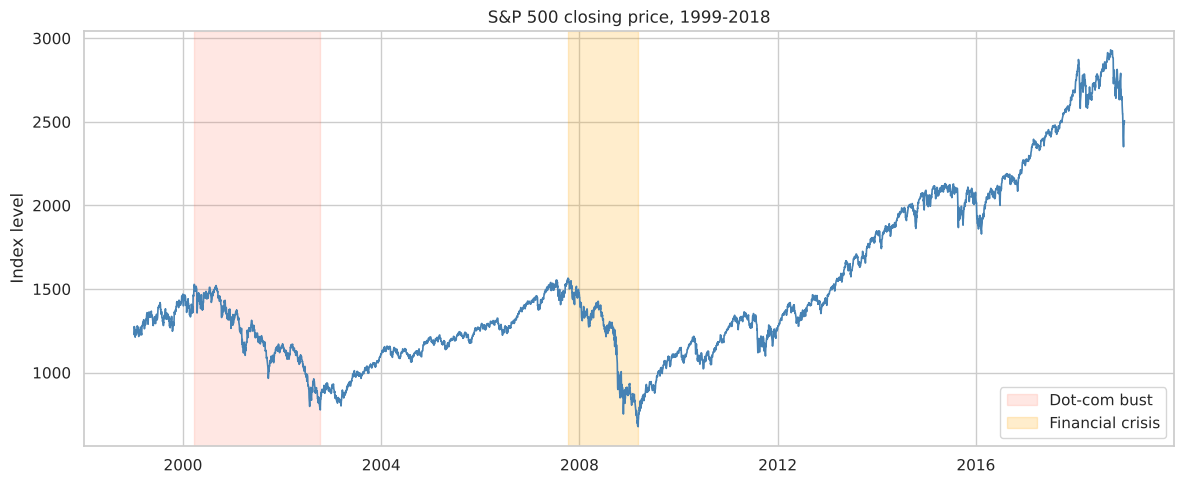

In [2]:
price = df["Close"]
df["ret"] = np.log(price).diff()           # daily log return

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(price, color="steelblue", lw=1.2)
ax.axvspan("2000-03-24", "2002-10-09", color="tomato", alpha=0.15, label="Dot-com bust")
ax.axvspan("2007-10-09", "2009-03-09", color="orange", alpha=0.20, label="Financial crisis")
ax.set_title("S&P 500 closing price, 1999-2018")
ax.set_ylabel("Index level")
ax.legend()
plt.tight_layout()
plt.savefig("fin_price_history.png", dpi=150)
plt.show()

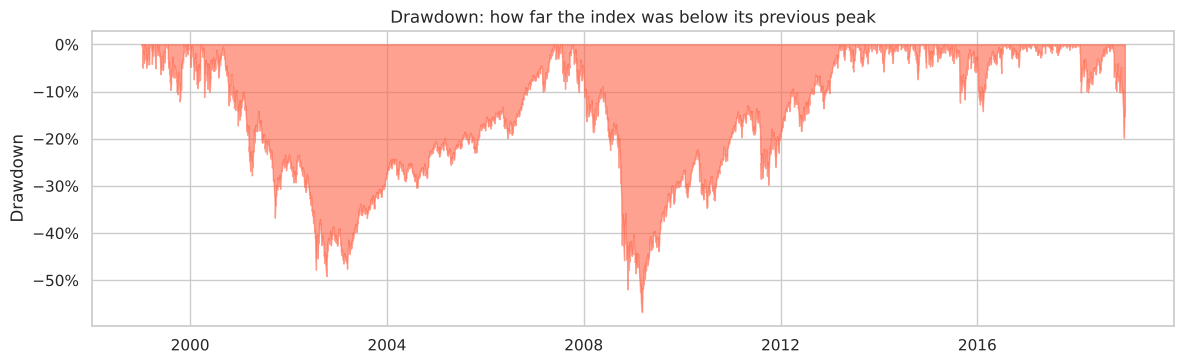

Max drawdown: -56.8% on 2009-03-09


In [3]:
running_max = price.cummax()
drawdown = price / running_max - 1

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.fill_between(drawdown.index, drawdown, 0, color="tomato", alpha=0.6)
ax.set_title("Drawdown: how far the index was below its previous peak")
ax.set_ylabel("Drawdown")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig("fin_drawdown.png", dpi=150)
plt.show()

print(f"Max drawdown: {drawdown.min():.1%} on {drawdown.idxmin().date()}")

## 3. Returns and risk

In [4]:
r = df["ret"].dropna()
summary = pd.Series({
    "Average annual return": r.mean() * 252,
    "Annual volatility": r.std() * np.sqrt(252),
    "Best day": r.max(),
    "Worst day": r.min(),
    "% of days up": (r > 0).mean(),
    "Skewness": r.skew(),
    "Excess kurtosis": r.kurt(),
})
print(summary.round(4).to_string())
print("\nBest day:", r.idxmax().date(), "| Worst day:", r.idxmin().date())

Average annual return    0.0357
Annual volatility        0.1911
Best day                 0.1096
Worst day               -0.0947
% of days up             0.5312
Skewness                -0.2047
Excess kurtosis          8.1785

Best day: 2008-10-13 | Worst day: 2008-10-15


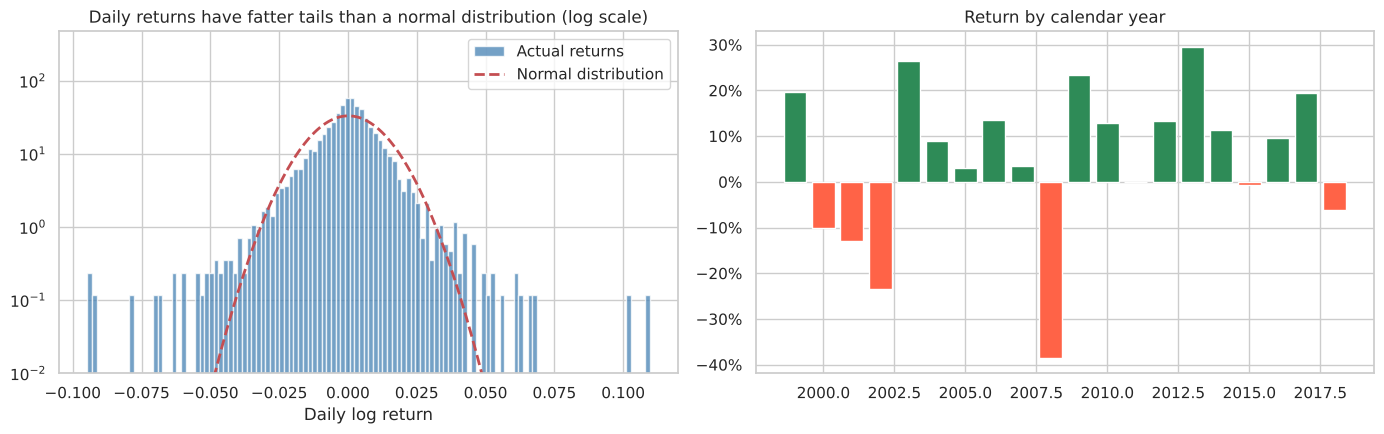

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Distribution vs normal
axes[0].hist(r, bins=120, density=True, color="steelblue", alpha=0.75, label="Actual returns")
xs = np.linspace(r.min(), r.max(), 400)
axes[0].plot(xs, stats.norm.pdf(xs, r.mean(), r.std()), "r--", lw=2, label="Normal distribution")
axes[0].set_yscale("log")
axes[0].set_ylim(bottom=1e-2)
axes[0].set_title("Daily returns have fatter tails than a normal distribution (log scale)")
axes[0].set_xlabel("Daily log return")
axes[0].legend()

# Yearly returns
yearly = np.exp(r.groupby(r.index.year).sum()) - 1
colors = ["seagreen" if v > 0 else "tomato" for v in yearly]
axes[1].bar(yearly.index, yearly.values, color=colors)
axes[1].set_title("Return by calendar year")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig("fin_returns_distribution.png", dpi=150)
plt.show()

### Volatility clustering
Big moves tend to follow big moves, and calm periods follow calm periods. This matters a lot for prediction.

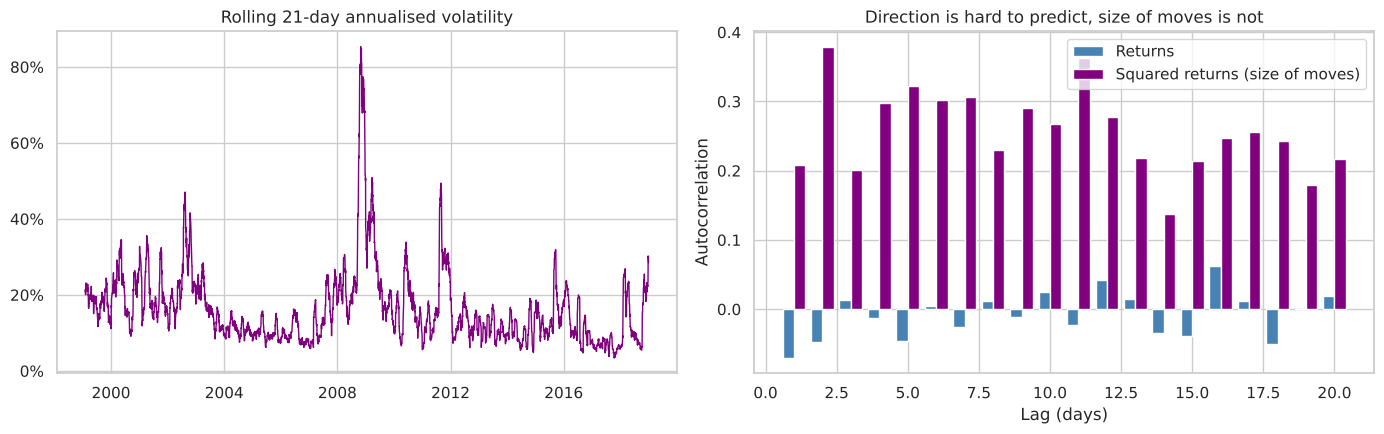

Autocorrelation of returns at lag 1:         -0.07
Autocorrelation of squared returns at lag 1: 0.208


In [6]:
roll_vol = r.rolling(21).std() * np.sqrt(252)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(roll_vol, color="purple", lw=1)
axes[0].set_title("Rolling 21-day annualised volatility")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

lags = range(1, 21)
ac_ret = [r.autocorr(l) for l in lags]
ac_sq = [(r ** 2).autocorr(l) for l in lags]
w = 0.4
axes[1].bar(np.array(lags) - w / 2, ac_ret, width=w, label="Returns", color="steelblue")
axes[1].bar(np.array(lags) + w / 2, ac_sq, width=w, label="Squared returns (size of moves)", color="purple")
axes[1].set_xlabel("Lag (days)")
axes[1].set_ylabel("Autocorrelation")
axes[1].set_title("Direction is hard to predict, size of moves is not")
axes[1].legend()
plt.tight_layout()
plt.savefig("fin_volatility_clustering.png", dpi=150)
plt.show()

print("Autocorrelation of returns at lag 1:        ", round(r.autocorr(1), 3))
print("Autocorrelation of squared returns at lag 1:", round((r**2).autocorr(1), 3))

## 4. Feature engineering
Everything below uses only information available **at the close of day t**. The targets describe day **t+1**.

| Feature | Meaning |
|---|---|
| `ret_today`, `ret_lag1..4` | today's return and the previous 4 days |
| `abs_ret_today` | size of today's move |
| `mom_5`, `mom_21` | 5-day and 21-day price momentum |
| `vol_5`, `vol_21` | recent volatility |
| `range_today` | (High - Low) / Close, intraday range |
| `vol_chg` | change in trading volume |
| `ma50_gap` | distance of price from its 50-day average |

**Targets**
- `y_dir`: 1 if tomorrow's return is positive
- `y_vol`: 1 if tomorrow is a **big-move day** (absolute return above 1%)

In [7]:
feat = pd.DataFrame(index=df.index)
feat["ret_today"] = df["ret"]
for k in range(1, 5):
    feat[f"ret_lag{k}"] = df["ret"].shift(k)
feat["abs_ret_today"] = df["ret"].abs()
feat["mom_5"] = np.log(price).diff(5)
feat["mom_21"] = np.log(price).diff(21)
feat["vol_5"] = df["ret"].rolling(5).std()
feat["vol_21"] = df["ret"].rolling(21).std()
feat["range_today"] = (df["High"] - df["Low"]) / df["Close"]
feat["vol_chg"] = np.log(df["Volume"]).diff()
feat["ma50_gap"] = price / price.rolling(50).mean() - 1

next_ret = df["ret"].shift(-1)
data = feat.copy()
data["y_dir"] = (next_ret > 0).astype(int)
data["y_vol"] = (next_ret.abs() > 0.01).astype(int)
data = data[next_ret.notna()].dropna()

print("Usable rows:", len(data))
data.head()

Usable rows: 4981


,ret_today,ret_lag1,ret_lag2,ret_lag3,ret_lag4,abs_ret_today,mom_5,mom_21,vol_5,vol_21,range_today,vol_chg,ma50_gap,y_dir,y_vol
Date,,,,,,,,,,,,,,,
1999-03-16,-0.000673,0.009739,-0.002384,0.008389,0.005455,0.000673,0.020525,0.060140,0.005405,0.010684,0.006751,0.033402,0.042127,0,0
1999-03-17,-0.006574,-0.000673,0.009739,-0.002384,0.008389,0.006574,0.008496,0.044068,0.007074,0.010760,0.010726,0.000532,0.034148,1,1
1999-03-18,0.014329,-0.006574,-0.000673,0.009739,-0.002384,0.014329,0.014437,0.072866,0.008773,0.010371,0.017371,0.099495,0.047874,0,1
1999-03-19,-0.013197,0.014329,-0.006574,-0.000673,0.009739,0.013197,0.003624,0.048903,0.011351,0.010836,0.019164,0.095966,0.033693,0,0
1999-03-22,-0.001756,-0.013197,0.014329,-0.006574,-0.000673,0.001756,-0.007872,0.045579,0.010171,0.010872,0.007386,-0.329087,0.031431,0,1


## 5. Chronological train / test split
Train on 1999-2013 (includes both crashes), test on 2014-2018 (data the model has never seen).

In [8]:
split = "2014-01-01"
train, test = data[data.index < split], data[data.index >= split]
feature_cols = list(feat.columns)

X_train, X_test = train[feature_cols], test[feature_cols]
print("Train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
print("Test: ", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")
print()
print("Share of UP days    | train:", round(train.y_dir.mean(), 3), "| test:", round(test.y_dir.mean(), 3))
print("Share of BIG-MOVE days | train:", round(train.y_vol.mean(), 3), "| test:", round(test.y_vol.mean(), 3))

Train: 1999-03-16 to 2013-12-31 (3724 days)
Test:  2014-01-02 to 2018-12-28 (1257 days)

Share of UP days    | train: 0.531 | test: 0.532
Share of BIG-MOVE days | train: 0.312 | test: 0.181


The test period (2014-2018) was much calmer than the training period, so big-move days are rarer there. That means plain accuracy can be misleading for the volatility task, so we also use **ROC-AUC**, which is not affected by that shift.

## 6. Train and evaluate the models
For each task we compare a **baseline** (always predict the most common class from training) against Logistic Regression and Random Forest.

In [9]:
def make_models():
    return {
        "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=20,
                                                random_state=42, n_jobs=-1),
    }

def run_task(target):
    models = make_models()
    rows, probs = [], {}
    for name, m in models.items():
        m.fit(X_train, train[target])
        pred = m.predict(X_test)
        proba = m.predict_proba(X_test)[:, 1]
        probs[name] = proba
        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(test[target], pred),
            "Precision": precision_score(test[target], pred, zero_division=0),
            "Recall": recall_score(test[target], pred, zero_division=0),
            "ROC-AUC": 0.5 if name.startswith("Baseline") else roc_auc_score(test[target], proba),
        })
    return models, pd.DataFrame(rows).set_index("Model").round(3), probs

dir_models, dir_res, dir_probs = run_task("y_dir")
vol_models, vol_res, vol_probs = run_task("y_vol")

print("TASK A: predict next-day DIRECTION (up / down)")
display(dir_res)
print("TASK B: predict next-day BIG MOVE (|return| > 1%)")
display(vol_res)

TASK A: predict next-day DIRECTION (up / down)


,Accuracy,Precision,Recall,ROC-AUC
Model,,,,
Baseline (majority class),0.532,0.532,1.000,0.500
Logistic Regression,0.532,0.533,0.978,0.532
Random Forest,0.531,0.536,0.883,0.512


TASK B: predict next-day BIG MOVE (|return| > 1%)


,Accuracy,Precision,Recall,ROC-AUC
Model,,,,
Baseline (majority class),0.819,0.000,0.000,0.500
Logistic Regression,0.820,0.516,0.145,0.793
Random Forest,0.829,0.597,0.175,0.815


## 7. ROC curves and confusion matrices

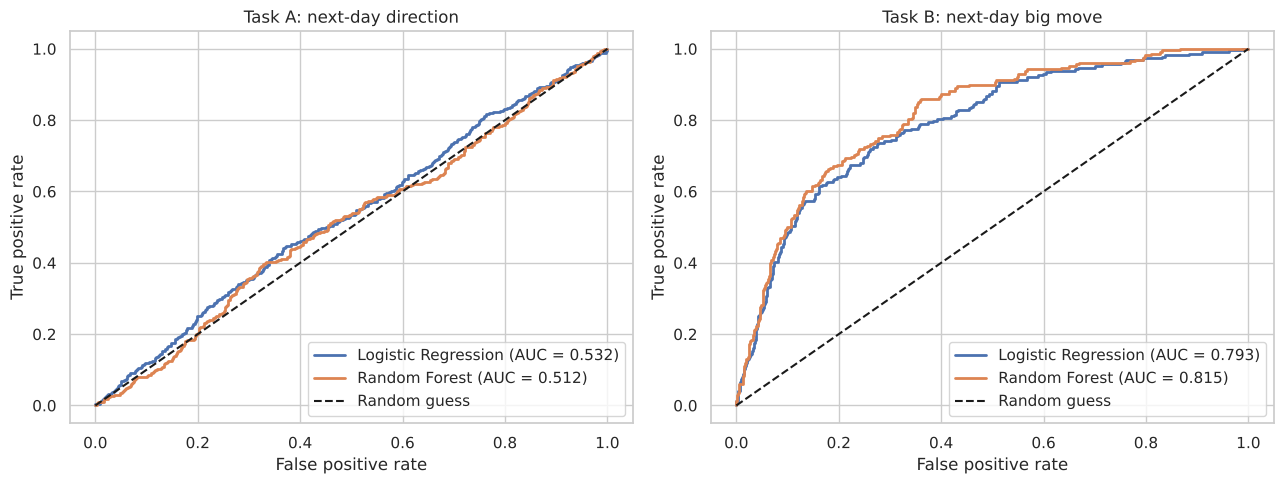

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, target, probs) in zip(axes, [("Task A: next-day direction", "y_dir", dir_probs),
                                              ("Task B: next-day big move", "y_vol", vol_probs)]):
    for name in ["Logistic Regression", "Random Forest"]:
        fpr, tpr, _ = roc_curve(test[target], probs[name])
        ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(test[target], probs[name]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", label="Random guess")
    ax.set_title(title)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("fin_roc_curves.png", dpi=150)
plt.show()

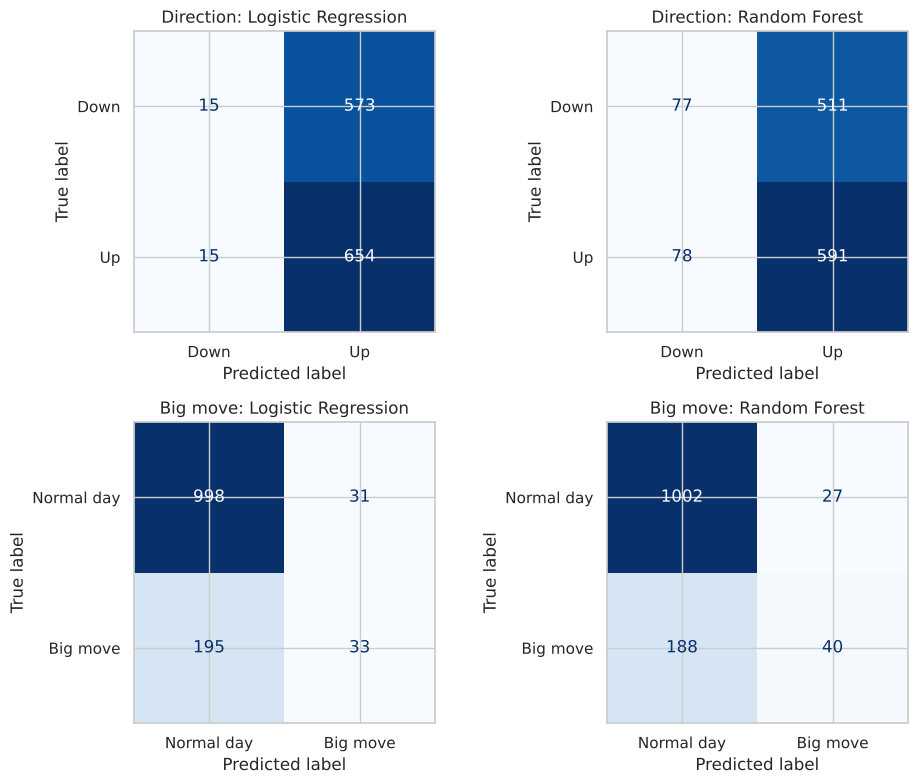

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
setups = [("Direction", "y_dir", dir_models, ["Down", "Up"]),
          ("Big move", "y_vol", vol_models, ["Normal day", "Big move"])]
for row, (label, target, models, names) in zip(axes, setups):
    for ax, mname in zip(row, ["Logistic Regression", "Random Forest"]):
        ConfusionMatrixDisplay.from_estimator(models[mname], X_test, test[target],
                                              display_labels=names, cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(f"{label}: {mname}")
plt.tight_layout()
plt.savefig("fin_confusion_matrices.png", dpi=150)
plt.show()

## 8. What drives the predictions?

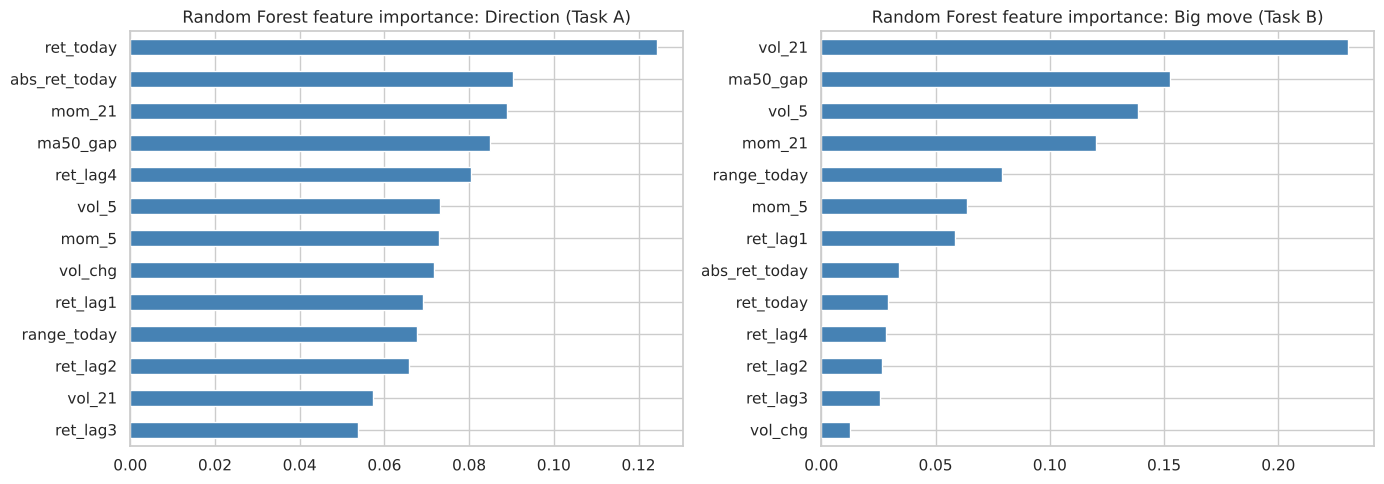

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (title, models) in zip(axes, [("Direction (Task A)", dir_models), ("Big move (Task B)", vol_models)]):
    imp = pd.Series(models["Random Forest"].feature_importances_, index=feature_cols).sort_values()
    imp.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"Random Forest feature importance: {title}")
plt.tight_layout()
plt.savefig("fin_feature_importance.png", dpi=150)
plt.show()

## 9. Using the volatility model in practice: ranking days by risk
At the default 0.5 cut-off the model flags very few big-move days (low recall). A more useful view is to **rank test days by predicted risk** and check how often big moves happen in the riskiest groups. If the model works, the highest-risk group should contain far more big-move days than average.

Overall share of big-move days in the test period: 18.1%

risk_group
1 (lowest risk)      3.6
2                    4.4
3                   12.7
4                   19.5
5 (highest risk)    50.4

Highest-risk group is 2.8x the average rate; lowest-risk group is 0.2x.


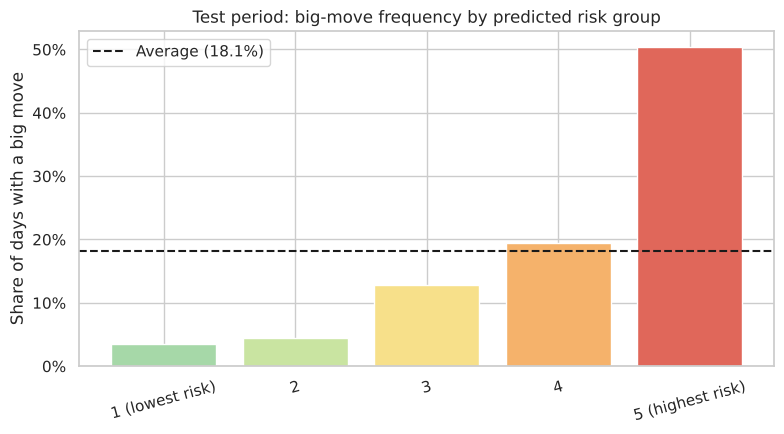

In [13]:
res = test[["y_vol"]].copy()
res["risk"] = vol_probs["Random Forest"]
res["risk_group"] = pd.qcut(res["risk"], 5, labels=["1 (lowest risk)", "2", "3", "4", "5 (highest risk)"])

rate = res.groupby("risk_group", observed=True)["y_vol"].mean()
base_rate = res["y_vol"].mean()
print(f"Overall share of big-move days in the test period: {base_rate:.1%}\n")
print((rate * 100).round(1).rename("% big-move days").to_string())
print(f"\nHighest-risk group is {rate.iloc[-1] / base_rate:.1f}x the average rate; "
      f"lowest-risk group is {rate.iloc[0] / base_rate:.1f}x.")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(5), rate.values, color=["#a6d8a8", "#c9e4a1", "#f7e08a", "#f5b26b", "#e0675a"])
ax.axhline(base_rate, color="k", ls="--", label=f"Average ({base_rate:.1%})")
ax.set_xticks(range(5))
ax.set_xticklabels(rate.index, rotation=15)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("Share of days with a big move")
ax.set_title("Test period: big-move frequency by predicted risk group")
ax.legend()
plt.tight_layout()
plt.savefig("fin_risk_groups.png", dpi=150)
plt.show()

## 10. Findings and conclusions

### What the market data shows
1. **Two major crashes dominate the period.** The index fell **56.8%** from its previous peak to the low on **9 March 2009**. The dot-com bust (2000-2002) was the other large drawdown.
2. **Modest long-run return, high risk.** Average return was about **3.6% a year** with annual volatility of about **19.1%**. Over these 20 years, the crashes took back much of what the good years gave.
3. **Returns are not normally distributed.** Excess kurtosis is **8.2**, so extreme days are far more common than a bell curve predicts. The best day (13 Oct 2008) and worst day (15 Oct 2008) were only two days apart, at the height of the crisis.
4. **Volatility clusters.** The autocorrelation of daily returns at lag 1 is only **-0.07**, but for squared returns (the size of moves) it is **0.21**. Direction looks close to random from one day to the next, while the size of moves is persistent.

### What the models show
| Task | Best model | Test accuracy | Baseline accuracy | ROC-AUC |
|---|---|---|---|---|
| A. Next-day direction (up/down) | Logistic Regression | 53.2% | 53.2% | **0.53** |
| B. Next-day big move (>1%) | Random Forest | 82.9% | 81.9% | **0.82** |

- **Task A: no real predictive power.** Both models matched the "always predict up" baseline (53.2%). ROC-AUC of 0.51-0.53 is barely above a coin flip, and the Random Forest's feature importances are spread almost evenly across all features, which is what noise looks like. This is consistent with the idea that daily index direction is very hard to forecast from past prices alone.
- **Task B: genuine signal.** ROC-AUC of **0.79-0.82** is well above chance. The Random Forest relies mostly on recent volatility (`vol_21` and `vol_5`), the distance from the 50-day average, and 21-day momentum. This matches the volatility-clustering finding above.
- **Accuracy alone is misleading for Task B** because big-move days were only 18% of the test period. At the default cut-off the model catches few of them (recall 17.5%), so the ROC-AUC and the risk ranking below are the fairer measures.
- **Risk ranking works.** Sorting test days into five groups by predicted risk, the highest group had big moves on **50.4%** of days (2.8x the average of 18.1%), while the lowest group had them on only **3.6%** (0.2x).

### Conclusion
The project shows an important real-world lesson: **in finance, predicting the *direction* of the market from past prices is extremely hard, but predicting *risk* is realistic.** Volatility is persistent, so a simple model can tell calm days from turbulent ones. This is how risk management uses data science in practice (position sizing, risk limits), rather than trying to call every up or down day.

### Limitations and next steps
- **Data ends in 2018** and covers a single index, so results may not hold for other markets or recent years.
- **Train and test periods differ.** Big-move days made up 31% of training days but only 18% of test days, because 2014-2018 was unusually calm. A different split could give different numbers.
- **Only price-based features were used.** Interest rates, earnings, news or the VIX index could add information.
- **No trading strategy was tested.** Even a good risk model would need transaction costs and a proper backtest before any real-world use.
- **Next steps:** try a GARCH volatility model as a benchmark, add more features, and use walk-forward validation across several test windows.

*This is a learning project, not financial advice.*
